In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
print("library loaded successfully")

library loaded successfully


In [14]:
file =r"C:\Users\RSC\Desktop\data sheets\project\data science project\transaction.csv"
df= pd.read_csv(file)
df.head()

,InvoiceNo,CustomerID,ProductID,Quantity,UnitPrice,InvoiceDate,LineRevenue
0,INV500001,C00001,P1002,1,54.35,06-07-2024,54.35
1,INV500001,C00001,P1012,2,111.43,06-07-2024,222.86
2,INV500002,C00001,P1018,2,10.47,23-07-2024,20.94
3,INV500003,C00001,P1006,3,117.15,10-09-2024,351.45
4,INV500004,C00001,P1022,3,44.48,31-10-2024,133.44


In [15]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (1000, 7)

Columns:
['InvoiceNo', 'CustomerID', 'ProductID', 'Quantity', 'UnitPrice', 'InvoiceDate', 'LineRevenue']


In [16]:
date_candidates = [
    "InvoiceDate", "TransactionDate",
    "OrderDate", "PurchaseDate", "Date"
]

date_col = next(
    (col for col in date_candidates if col in df.columns),
    None
)

if date_col is None:
    raise ValueError(
        "Date column not found. Check your dataset columns "
        "and update date_col manually."
    )

In [17]:
sales_candidates = [
    "LineRevenue", "Revenue", "Sales",
    "Amount", "TotalAmount", "OrderRevenue"
]

sales_col = next(
    (col for col in sales_candidates if col in df.columns),
    None
)

In [18]:
if sales_col is None:

    if {"Quantity", "UnitPrice"}.issubset(df.columns):
        df["Sales"] = df["Quantity"] * df["UnitPrice"]
        sales_col = "Sales"

    else:
        raise ValueError(
            "Sales column not found. Provide a revenue column "
            "or Quantity and UnitPrice columns."
        )

In [19]:
df[date_col] = pd.to_datetime(
    df[date_col],
    errors="coerce"
)

df[sales_col] = pd.to_numeric(
    df[sales_col],
    errors="coerce"
)

df = df.dropna(subset=[date_col, sales_col])

print("\nDate column:", date_col)
print("Sales column:", sales_col)
print("Valid records:", len(df))


Date column: InvoiceDate
Sales column: LineRevenue
Valid records: 375


In [20]:
df = df.sort_values(date_col)
df = df.set_index(date_col)

daily_sales = df[sales_col].resample("D").sum()

weekly_sales = df[sales_col].resample("W-SUN").sum()

monthly_sales = df[sales_col].resample("MS").sum()
df.head()

,InvoiceNo,CustomerID,ProductID,Quantity,UnitPrice,LineRevenue
InvoiceDate,,,,,,
2024-01-01,INV500174,C00025,P1005,1,14.02,14.02
2024-01-01,INV500223,C00033,P1009,1,17.99,17.99
2024-01-01,INV500174,C00025,P1021,3,91.70,275.10
2024-01-01,INV500223,C00033,P1004,1,84.59,84.59
2024-01-02,INV500314,C00048,P1006,1,117.15,117.15


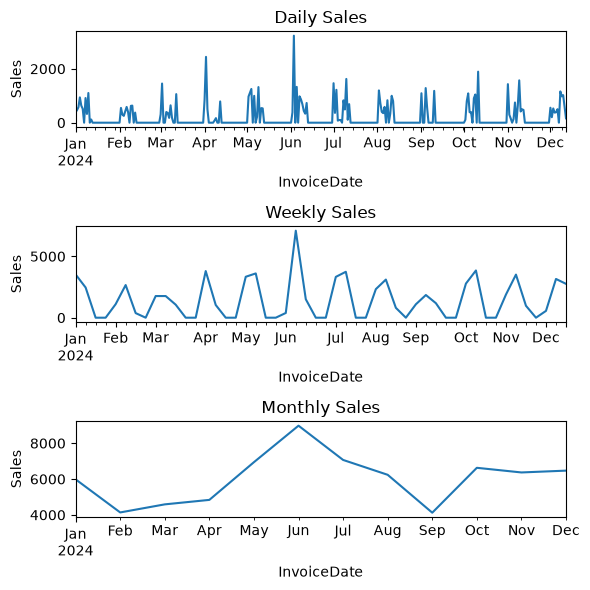

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(6, 6))

daily_sales.plot(ax=axes[0])
axes[0].set_title("Daily Sales")
axes[0].set_ylabel("Sales")

weekly_sales.plot(ax=axes[1])
axes[1].set_title("Weekly Sales")
axes[1].set_ylabel("Sales")

monthly_sales.plot(ax=axes[2])
axes[2].set_title("Monthly Sales")
axes[2].set_ylabel("Sales")

plt.tight_layout()
plt.show()

In [23]:
def evaluate_forecasting(series, frequency, window):

    series = series.astype(float).dropna()

    if len(series) < 10:
        print(
            f"Not enough {frequency} observations "
            "for reliable chronological evaluation."
        )
        return None, None

    split_index = int(len(series) * 0.80)

    train = series.iloc[:split_index]
    test = series.iloc[split_index:]
    naive_predictions = []
    
    moving_average_predictions = []

    history = list(train.values)

    for actual_value in test.values:

        naive_predictions.append(history[-1])

        moving_average_predictions.append(
            np.mean(history[-window:])
        )

        history.append(actual_value)

    naive_predictions = np.array(naive_predictions)
    moving_average_predictions = np.array(
        moving_average_predictions
    )

    actual = test.values
    naive_mae = np.mean(
        np.abs(actual - naive_predictions)
    )

    moving_mae = np.mean(
        np.abs(actual - moving_average_predictions)
    )

    nonzero_mask = actual != 0

    if nonzero_mask.any():

        naive_mape = np.mean(
            np.abs(
                (actual[nonzero_mask] -
                 naive_predictions[nonzero_mask]) /
                actual[nonzero_mask]
            )
        ) * 100

        moving_mape = np.mean(
            np.abs(
                (actual[nonzero_mask] -
                 moving_average_predictions[nonzero_mask]) /
                actual[nonzero_mask]
            )
        ) * 100

    else:
        naive_mape = np.nan
        moving_mape = np.nan

    results = pd.DataFrame({
        "Actual": actual,
        "Naive_Forecast": naive_predictions,
        "Moving_Average_Forecast": moving_average_predictions
    }, index=test.index)

    metrics = pd.DataFrame({
        "Frequency": [frequency, frequency],
        "Model": ["Naive", "Moving Average"],
        "MAE": [naive_mae, moving_mae],
        "MAPE_Percent": [naive_mape, moving_mape],
        "MAPE_Valid_Observations": [
            int(nonzero_mask.sum()),
            int(nonzero_mask.sum())
        ],
        "Training_Observations": [len(train), len(train)],
        "Testing_Observations": [len(test), len(test)]
    })

    return metrics, results



forecast_settings = {
    "Daily": (daily_sales, 7),
    "Weekly": (weekly_sales, 4),
    "Monthly": (monthly_sales, 3)
}

all_metrics = {}
all_forecasts = {}

for frequency, (series, window) in forecast_settings.items():

    metrics, forecasts = evaluate_forecasting(
        series,
        frequency,
        window
    )

    if metrics is not None:

        all_metrics[frequency] = metrics
        all_forecasts[frequency] = forecasts

if not all_metrics:
    raise ValueError(
        "Insufficient observations for forecasting."
    )

comparison_df = pd.concat(
    all_metrics.values(),
    ignore_index=True
)

print("\n========== FORECAST MODEL COMPARISON ==========")
print(comparison_df.round(3))


========== FORECAST MODEL COMPARISON ==========
  Frequency           Model       MAE  MAPE_Percent  MAPE_Valid_Observations  \
0     Daily           Naive   274.247        92.574                       27   
1     Daily  Moving Average   275.005        61.761                       27   
2    Weekly           Naive  1549.413        90.340                        7   
3    Weekly  Moving Average  1496.909        69.847                        7   
4   Monthly           Naive   955.163        14.478                        3   
5   Monthly  Moving Average   762.738        11.747                        3   

   Training_Observations  Testing_Observations  
0                    277                    70  
1                    277                    70  
2                     40                    10  
3                     40                    10  
4                      9                     3  
5                      9                     3  


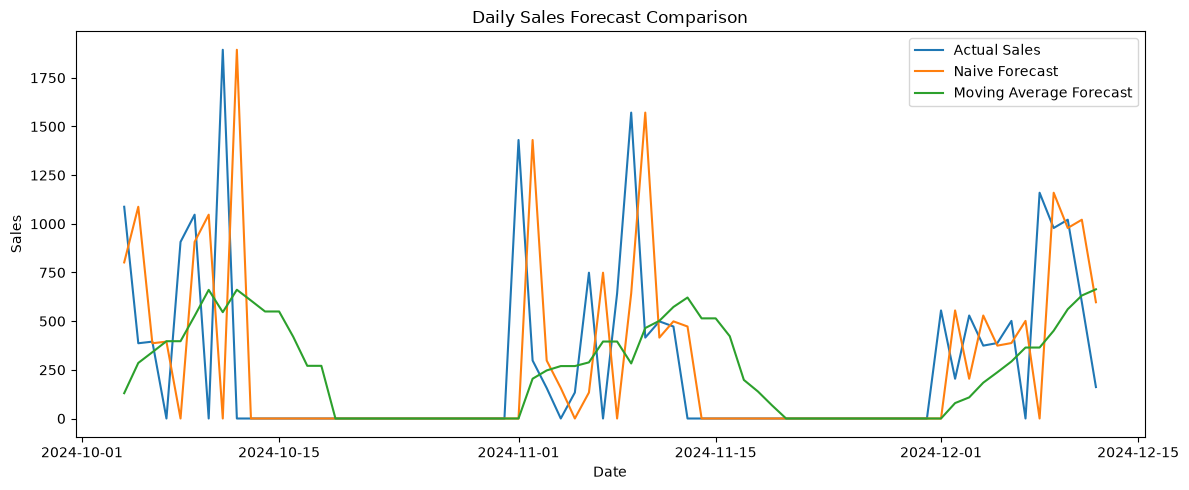

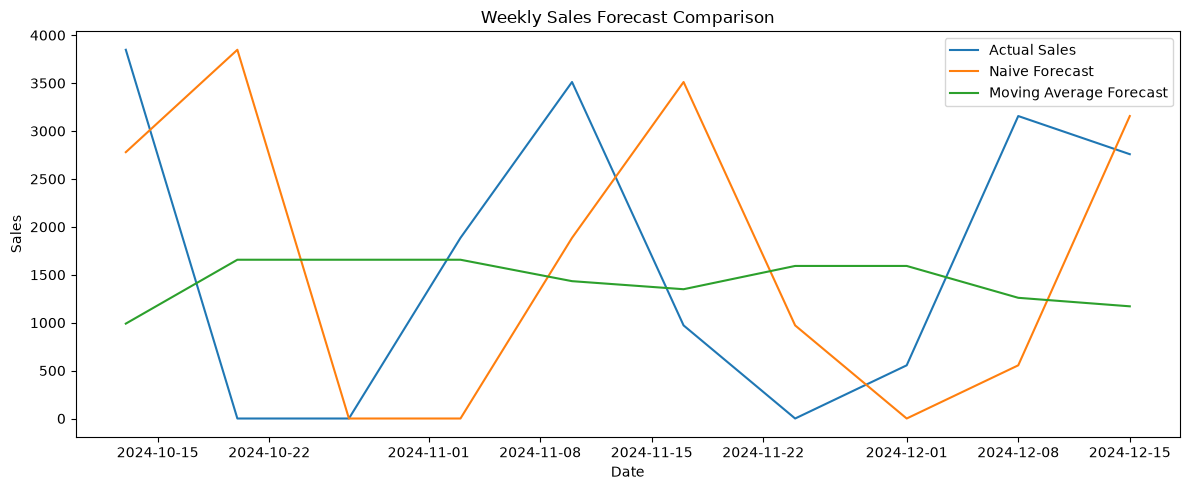

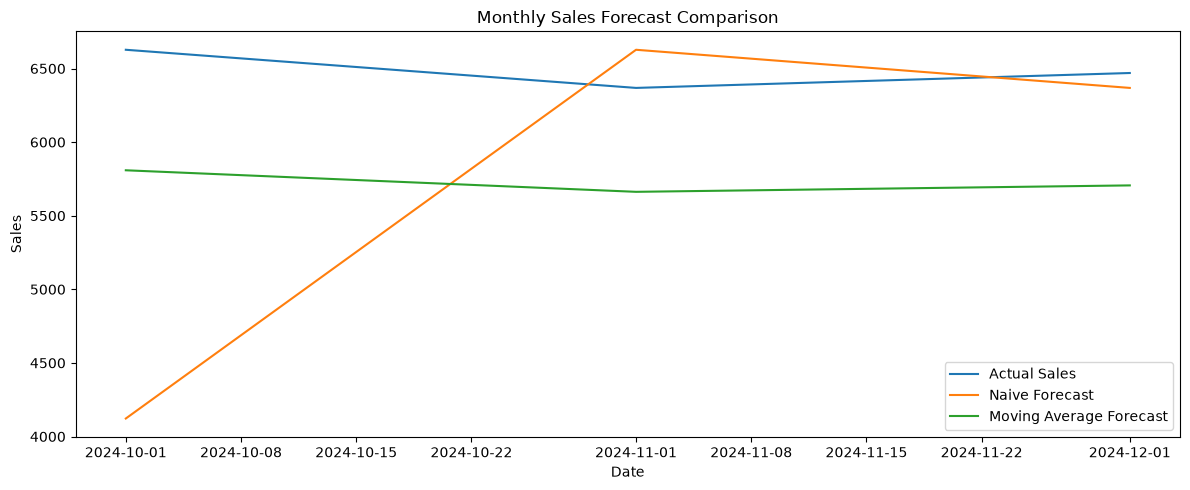

In [24]:
for frequency, forecasts in all_forecasts.items():

    plt.figure(figsize=(12, 5))

    plt.plot(
        forecasts.index,
        forecasts["Actual"],
        label="Actual Sales"
    )

    plt.plot(
        forecasts.index,
        forecasts["Naive_Forecast"],
        label="Naive Forecast"
    )

    plt.plot(
        forecasts.index,
        forecasts["Moving_Average_Forecast"],
        label="Moving Average Forecast"
    )

    plt.title(f"{frequency} Sales Forecast Comparison")
    plt.xlabel("Date")
    plt.ylabel("Sales")
    plt.legend()
    plt.tight_layout()
    plt.show()



In [25]:
for frequency, group in comparison_df.groupby("Frequency"):

    best_model = group.loc[group["MAE"].idxmin()]

    print(f"\nBest model for {frequency} sales:")
    print("Model:", best_model["Model"])
    print("MAE:", round(best_model["MAE"], 2))
    print("MAPE:", round(best_model["MAPE_Percent"], 2), "%")


Best model for Daily sales:
Model: Naive
MAE: 274.25
MAPE: 92.57 %

Best model for Monthly sales:
Model: Moving Average
MAE: 762.74
MAPE: 11.75 %

Best model for Weekly sales:
Model: Moving Average
MAE: 1496.91
MAPE: 69.85 %


In [26]:
OUTPUT_DIR = Path("model_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

daily_sales.to_csv(
    OUTPUT_DIR / "daily_sales.csv",
    header=["Sales"]
)

weekly_sales.to_csv(
    OUTPUT_DIR / "weekly_sales.csv",
    header=["Sales"]
)

monthly_sales.to_csv(
    OUTPUT_DIR / "monthly_sales.csv",
    header=["Sales"]
)

comparison_df.to_csv(
    OUTPUT_DIR / "sales_forecast_comparison.csv",
    index=False
)

for frequency, forecasts in all_forecasts.items():

    forecasts.to_csv(
        OUTPUT_DIR / f"{frequency.lower()}_forecast_results.csv"
    )

print("\n========== FORECASTING COMPLETED ==========")
print("Results saved to:", OUTPUT_DIR.resolve())



========== FORECASTING COMPLETED ==========
Results saved to: C:\Users\RSC\model_outputs
